In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=5)
SEED = 42
rng = np.random.default_rng(SEED)

## Task 1

array([1.03164, 1.94738])

array([0.97738, 1.64997])

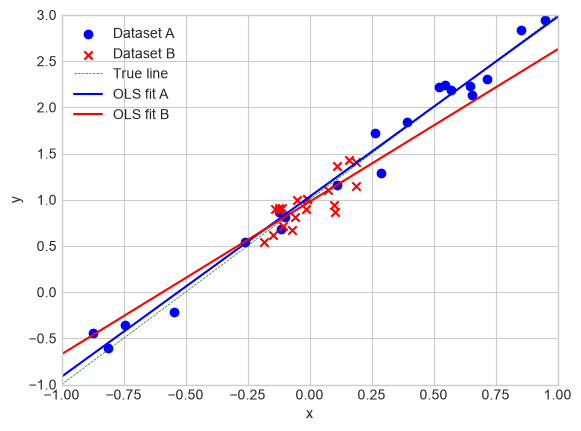

array([[ 1.     ,  0.10324],
       [ 1.     , -0.05819],
       [ 1.     ,  0.18828],
       [ 1.     ,  0.15725],
       [ 1.     ,  0.11135],
       [ 1.     , -0.12214],
       [ 1.     , -0.01331],
       [ 1.     , -0.18248],
       [ 1.     , -0.13828],
       [ 1.     ,  0.07322],
       [ 1.     ,  0.0979 ],
       [ 1.     ,  0.187  ],
       [ 1.     , -0.06967],
       [ 1.     , -0.05182],
       [ 1.     , -0.01218],
       [ 1.     , -0.12421],
       [ 1.     , -0.14803],
       [ 1.     , -0.00972],
       [ 1.     , -0.10924],
       [ 1.     , -0.10891]])

In [3]:
X_a: np.ndarray = rng.uniform(-1, 1, size=(20, 1))
X_a = np.pad(X_a, ((0, 0), (1, 0)), mode="constant", constant_values=1)  # pad with ones for the bias term

X_b: np.ndarray = rng.uniform(-0.2, 0.2, size=(19, 1))
X_b = np.pad(X_b, ((0, 0), (1, 0)), mode="constant", constant_values=1)  # pad with ones for the bias term
X_b = np.vstack((X_b, np.array([[1.0, X_b[-1, 1] + rng.normal(0, 0.0005)]])))  # add a near duplicate

# pick a constant w
w = np.array([1, 2])

# generate y_a and y_b with some noise
y_a = X_a @ w + rng.normal(0, 0.2, size=20)
y_b = X_b @ w + rng.normal(0, 0.2, size=20)


# compute best fit weights using the normal equation
w_a_best = np.linalg.inv(X_a.T @ X_a) @ X_a.T @ y_a
display(w_a_best)

w_b_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y_b
display(w_b_best)

plt.scatter(X_a[:, 1], y_a, label="Dataset A", color="blue", marker="o")
plt.scatter(X_b[:, 1], y_b, label="Dataset B", color="red", marker="x")
plt.plot(x := np.linspace(-1, 1, 100), w[0] + w[1] * x, label="True line", color="green", linestyle="--", linewidth=0.5)
plt.plot(x, w_a_best[0] + w_a_best[1] * x, label="OLS fit A", color="blue")
plt.plot(x, w_b_best[0] + w_b_best[1] * x, label="OLS fit B", color="red")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(-1, 1)
plt.ylim(-1, 3)
plt.legend()
plt.show()

display(X_b)

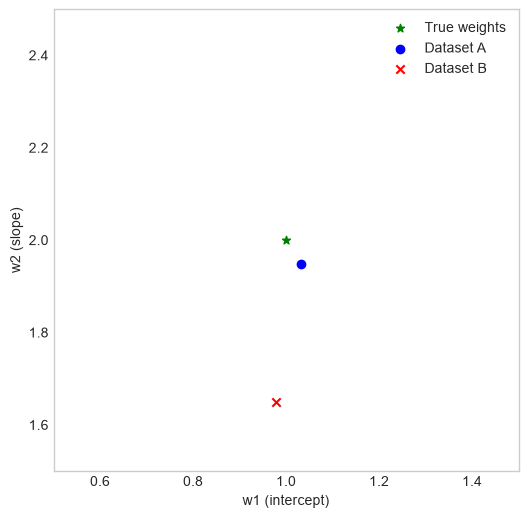

In [4]:
# plot the weights
plt.figure(figsize=(6,6))
plt.scatter(w[0], w[1], color="green", label="True weights", marker="*")
plt.scatter(w_a_best[0], w_a_best[1], color="blue", label="Dataset A", marker="o")
plt.scatter(w_b_best[0], w_b_best[1], color="red", label="Dataset B", marker="x")
plt.xlim(0.5, 1.5)
plt.ylim(1.5, 2.5)
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("w1 (intercept)")
plt.ylabel("w2 (slope)")
plt.axvline(0, color="black", lw=0.5)
plt.grid()
plt.legend()
plt.show()

Eigenvalues A: [ 5.96724 20.62171]  (cond = 3.46)
Eigenvalues B: [ 0.27029 20.00268]  (cond = 74.00)


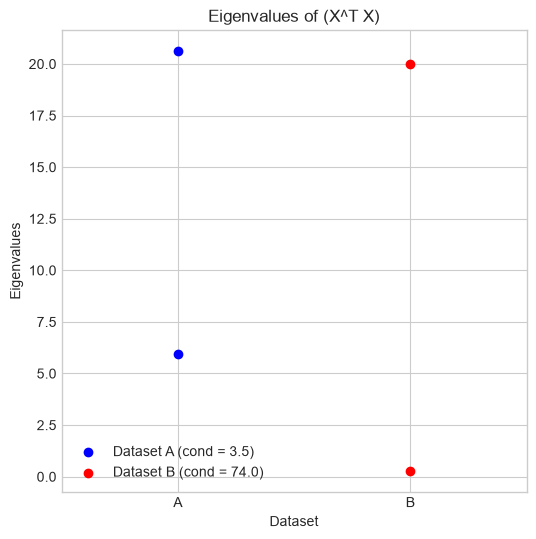

In [5]:
# eigenvalues of X^T X (symmetric, so eigh gives real eigenvalues in ascending order)
eig_a = np.linalg.eigh(X_a.T @ X_a)
eig_b = np.linalg.eigh(X_b.T @ X_b)

# compute condition numbers
cond_a = eig_a.eigenvalues[-1] / eig_a.eigenvalues[0]
cond_b = eig_b.eigenvalues[-1] / eig_b.eigenvalues[0]
print(f"Eigenvalues A: {eig_a.eigenvalues}  (cond = {cond_a:.2f})")
print(f"Eigenvalues B: {eig_b.eigenvalues}  (cond = {cond_b:.2f})")

# plot the eigenvalues
plt.figure(figsize=(6, 6))
plt.scatter([0] * len(eig_a.eigenvalues), eig_a.eigenvalues, color="blue", label=f"Dataset A (cond = {cond_a:.1f})")
plt.scatter([1] * len(eig_b.eigenvalues), eig_b.eigenvalues, color="red", label=f"Dataset B (cond = {cond_b:.1f})")
plt.xticks([0, 1], ["A", "B"])
plt.xlim(-0.5, 1.5)
plt.xlabel("Dataset")
plt.ylabel("Eigenvalues")
plt.title("Eigenvalues of (X^T X)")
plt.legend()
plt.show()

## Task 2: Ridge Regularization

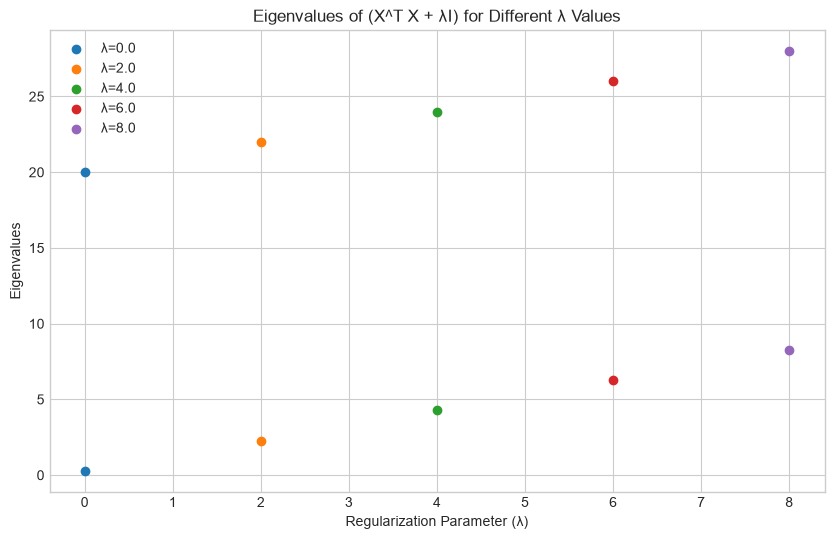

In [11]:
# generate new matrices with different lambdas
Ridge_matrices = []
lambdas = np.arange(0, 10, 2)

for lam in lambdas:
    matrix = X_b.T @ X_b + lam * np.eye(X_b.shape[1])
    eigenvalues, eigenvectors = np.linalg.eigh(matrix)
    Ridge_matrices.append({"lambda": lam, "matrix": matrix, "eigenvalues": eigenvalues, "eigenvectors": eigenvectors})

# plot eigenvalues for different lambdas
plt.figure(figsize=(10, 6))
for ridge_matrix in Ridge_matrices:
    plt.scatter(
        [ridge_matrix["lambda"]] * len(ridge_matrix["eigenvalues"]),
        ridge_matrix["eigenvalues"],
        label=f"λ={ridge_matrix['lambda']:.1f}",
    )
plt.xlabel("Regularization Parameter (λ)")
plt.ylabel("Eigenvalues")
plt.title("Eigenvalues of (X^T X + λI) for Different λ Values")
plt.legend()
plt.show()

### Plotting residues

$$r = y - X w$$

$$L = r^T r$$

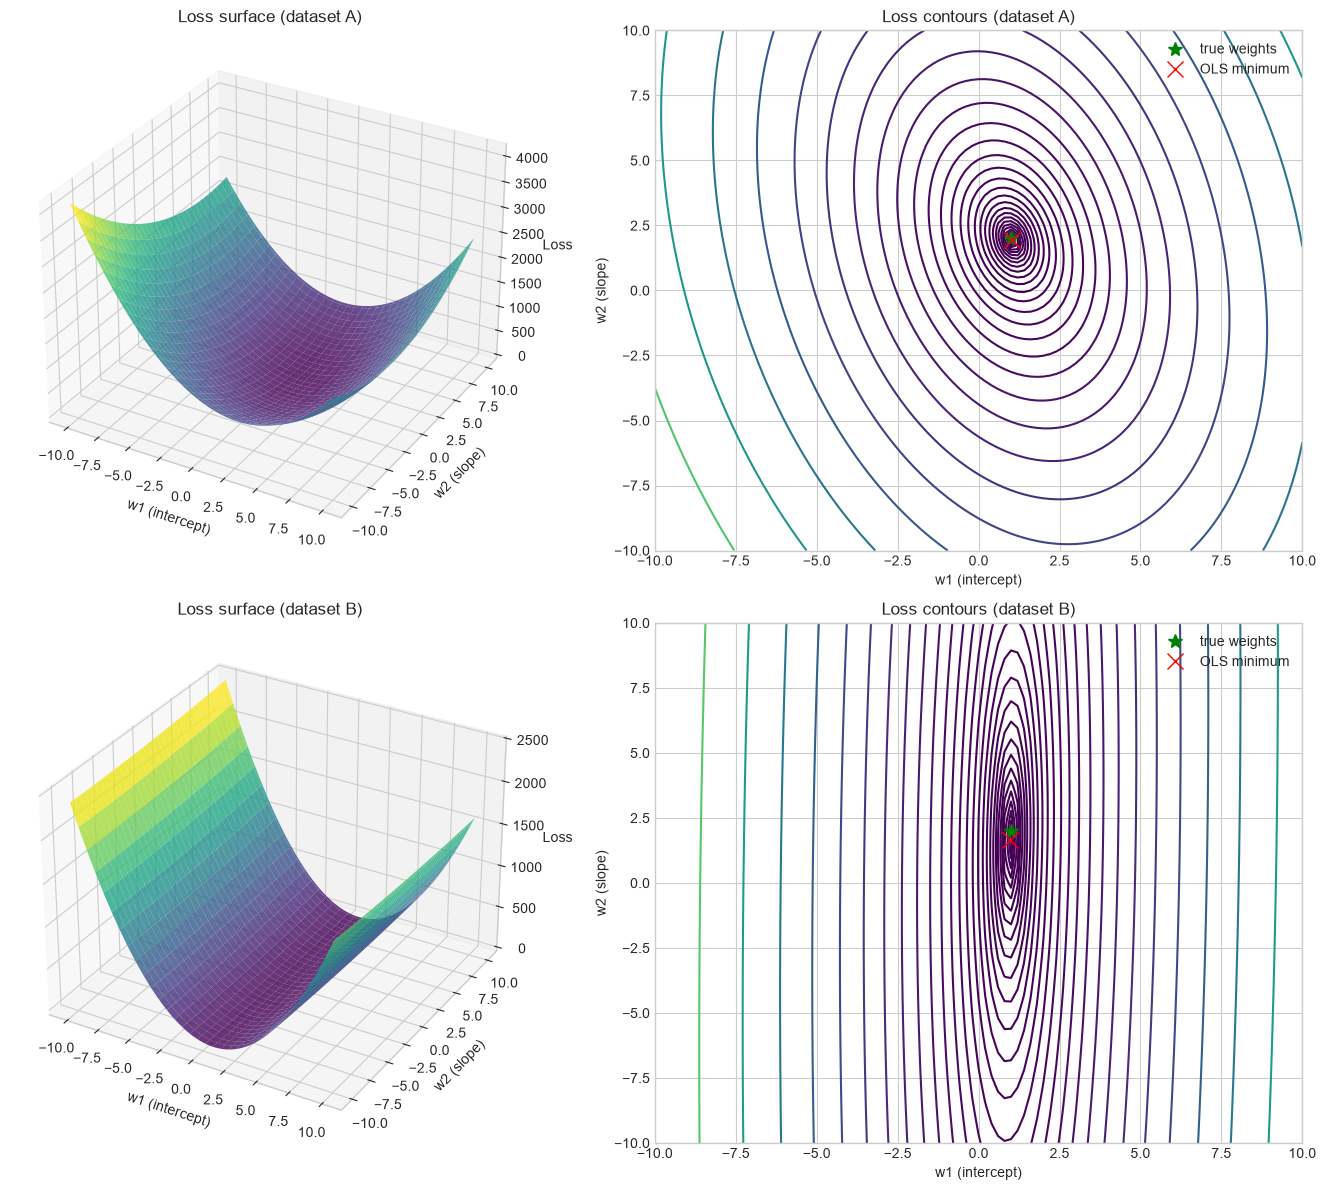

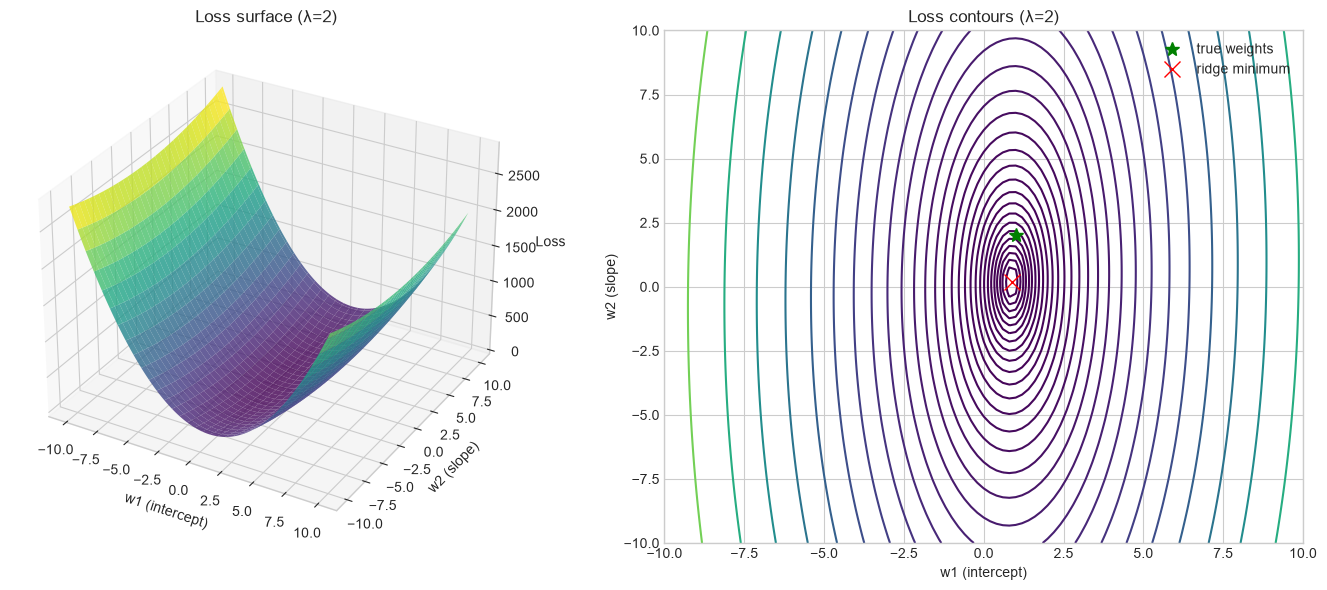

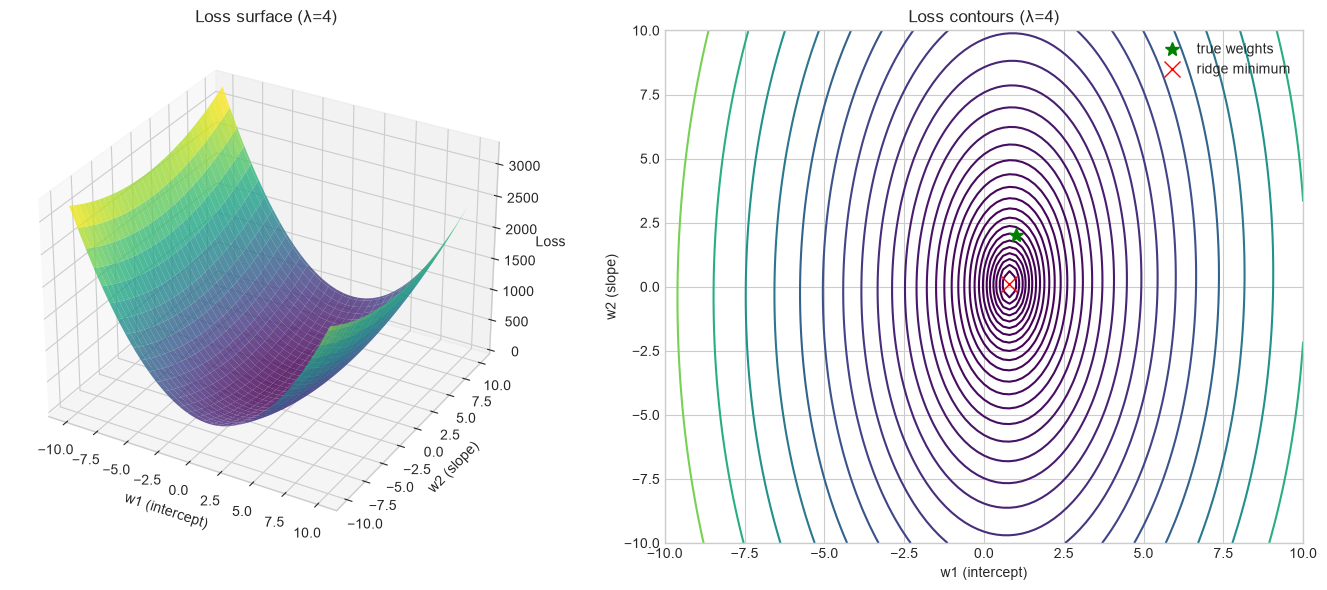

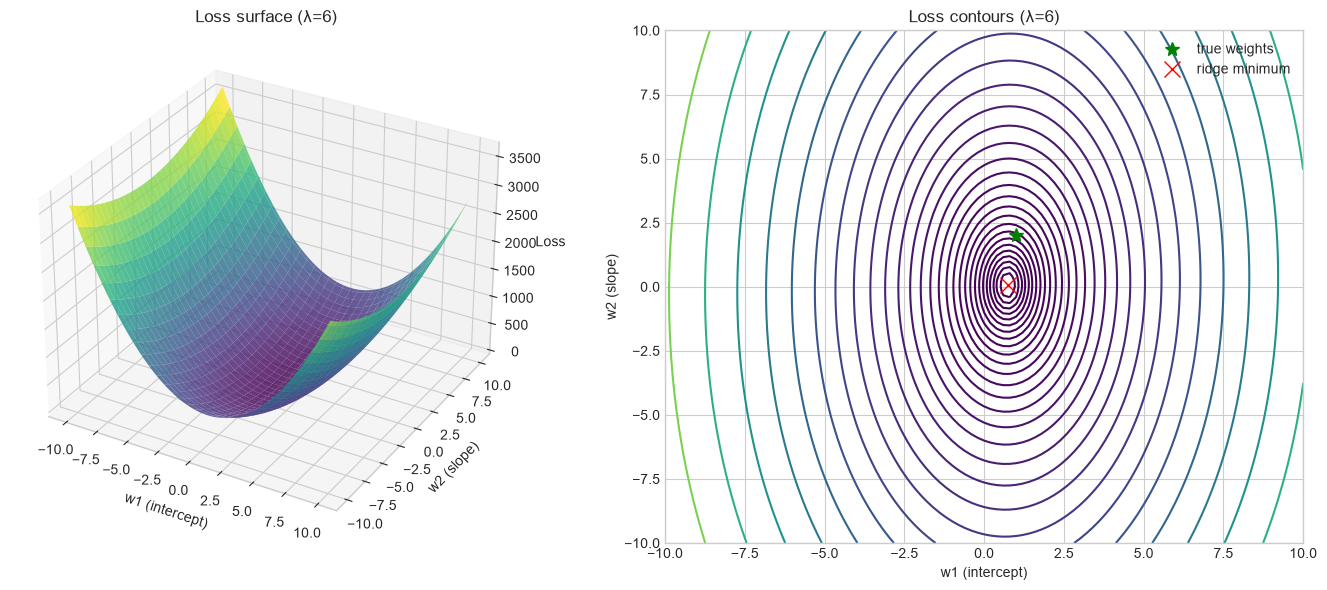

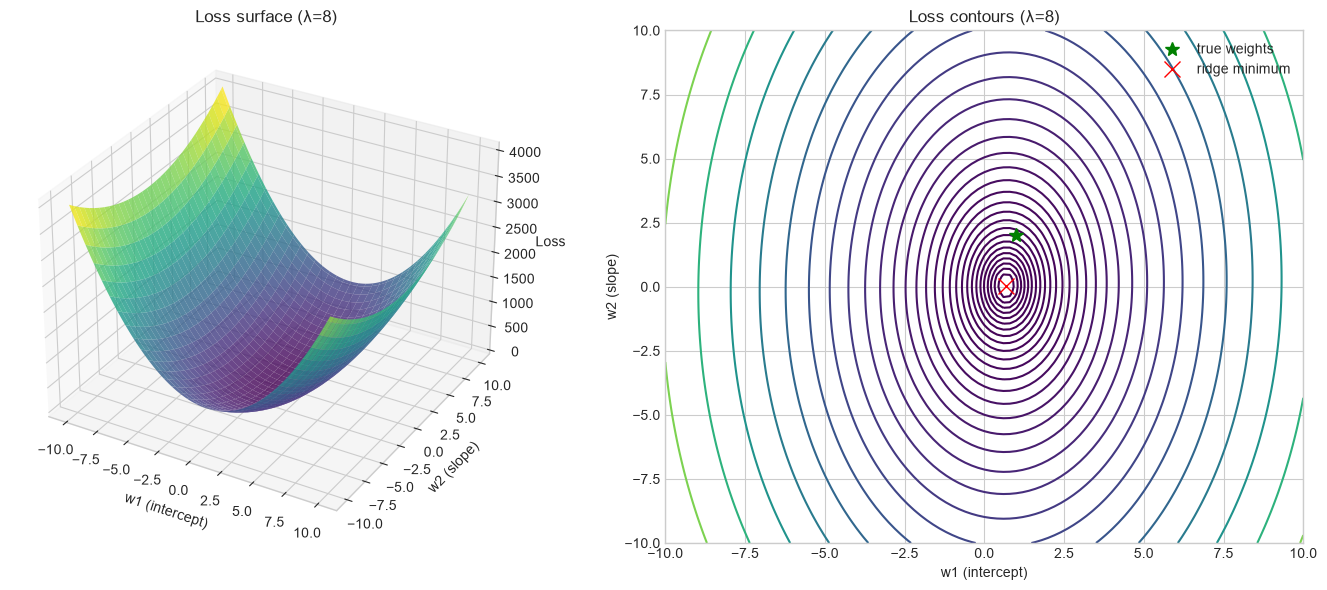

In [7]:
w_min, w_max, w_step = -10, 10, 0.2

# grid of candidate weights: W0[i, j] = w1 (intercept), W1[i, j] = w2 (slope)
w0_axis = np.arange(w_min, w_max + w_step, w_step)
w1_axis = np.arange(w_min, w_max + w_step, w_step)
W0, W1 = np.meshgrid(w0_axis, w1_axis)
W_grid = np.stack([W0.ravel(), W1.ravel()])  # shape (2, n_points)


def loss_surface(X, y):
    """Squared-error loss L = r^T r with r = y - X w, evaluated at every grid point at once."""
    R = y[:, None] - X @ W_grid  # shape (n_samples, n_points)
    return np.sum(R**2, axis=0).reshape(W0.shape)


def plot_loss(fig, n_rows, row, L, w_min_loss, title, min_label="OLS minimum"):
    """3D surface in column 1 and log-level contour plot in column 2 of the given row."""
    ax_3d = fig.add_subplot(n_rows, 2, 2 * row + 1, projection="3d")
    ax_3d.plot_surface(W0, W1, L, cmap="viridis", alpha=0.8)
    ax_3d.set_xlabel("w1 (intercept)")
    ax_3d.set_ylabel("w2 (slope)")
    ax_3d.set_zlabel("Loss")
    ax_3d.set_title(f"Loss surface ({title})")

    # log-spaced levels so the narrow valley is visible
    ax_c = fig.add_subplot(n_rows, 2, 2 * row + 2)
    levels = np.logspace(np.log10(L.min()), np.log10(L.max()), 30)
    ax_c.contour(W0, W1, L, levels=levels, cmap="viridis")
    ax_c.plot(w[0], w[1], "g*", markersize=10, label="true weights")
    ax_c.plot(*w_min_loss, "rx", markersize=12, label=min_label)
    ax_c.set_xlabel("w1 (intercept)")
    ax_c.set_ylabel("w2 (slope)")
    ax_c.set_title(f"Loss contours ({title})")
    ax_c.legend()


# datasets A and B: one row each
L_a = loss_surface(X_a, y_a)
L_b = loss_surface(X_b, y_b)

fig = plt.figure(figsize=(14, 12))
plot_loss(fig, 2, 0, L_a, w_a_best, "dataset A")
plot_loss(fig, 2, 1, L_b, w_b_best, "dataset B")
plt.tight_layout()
plt.show()

# dataset B with the ridge penalty: L = r^T r + lambda * w^T w, one figure per lambda
for ridge_matrix in Ridge_matrices[1:]:  # skip lambda=0, which is just OLS
    lam = ridge_matrix["lambda"]
    L_ridge = L_b + lam * (W0**2 + W1**2)
    w_ridge = np.linalg.solve(ridge_matrix["matrix"], X_b.T @ y_b)  # (X^T X + lambda I)^-1 X^T y

    fig = plt.figure(figsize=(14, 6))
    plot_loss(fig, 1, 0, L_ridge, w_ridge, f"λ={lam}", min_label="ridge minimum")
    plt.tight_layout()
    plt.show()

The loss surface is quadratic in w1 and in w2. The minimum is at the point where the gradient is zero, which corresponds to the point where the loss surface is flat. The ridge regularization term adds a penalty to the loss function that increases with the magnitude of the weights, which helps to prevent overfitting and encourages smaller weights.

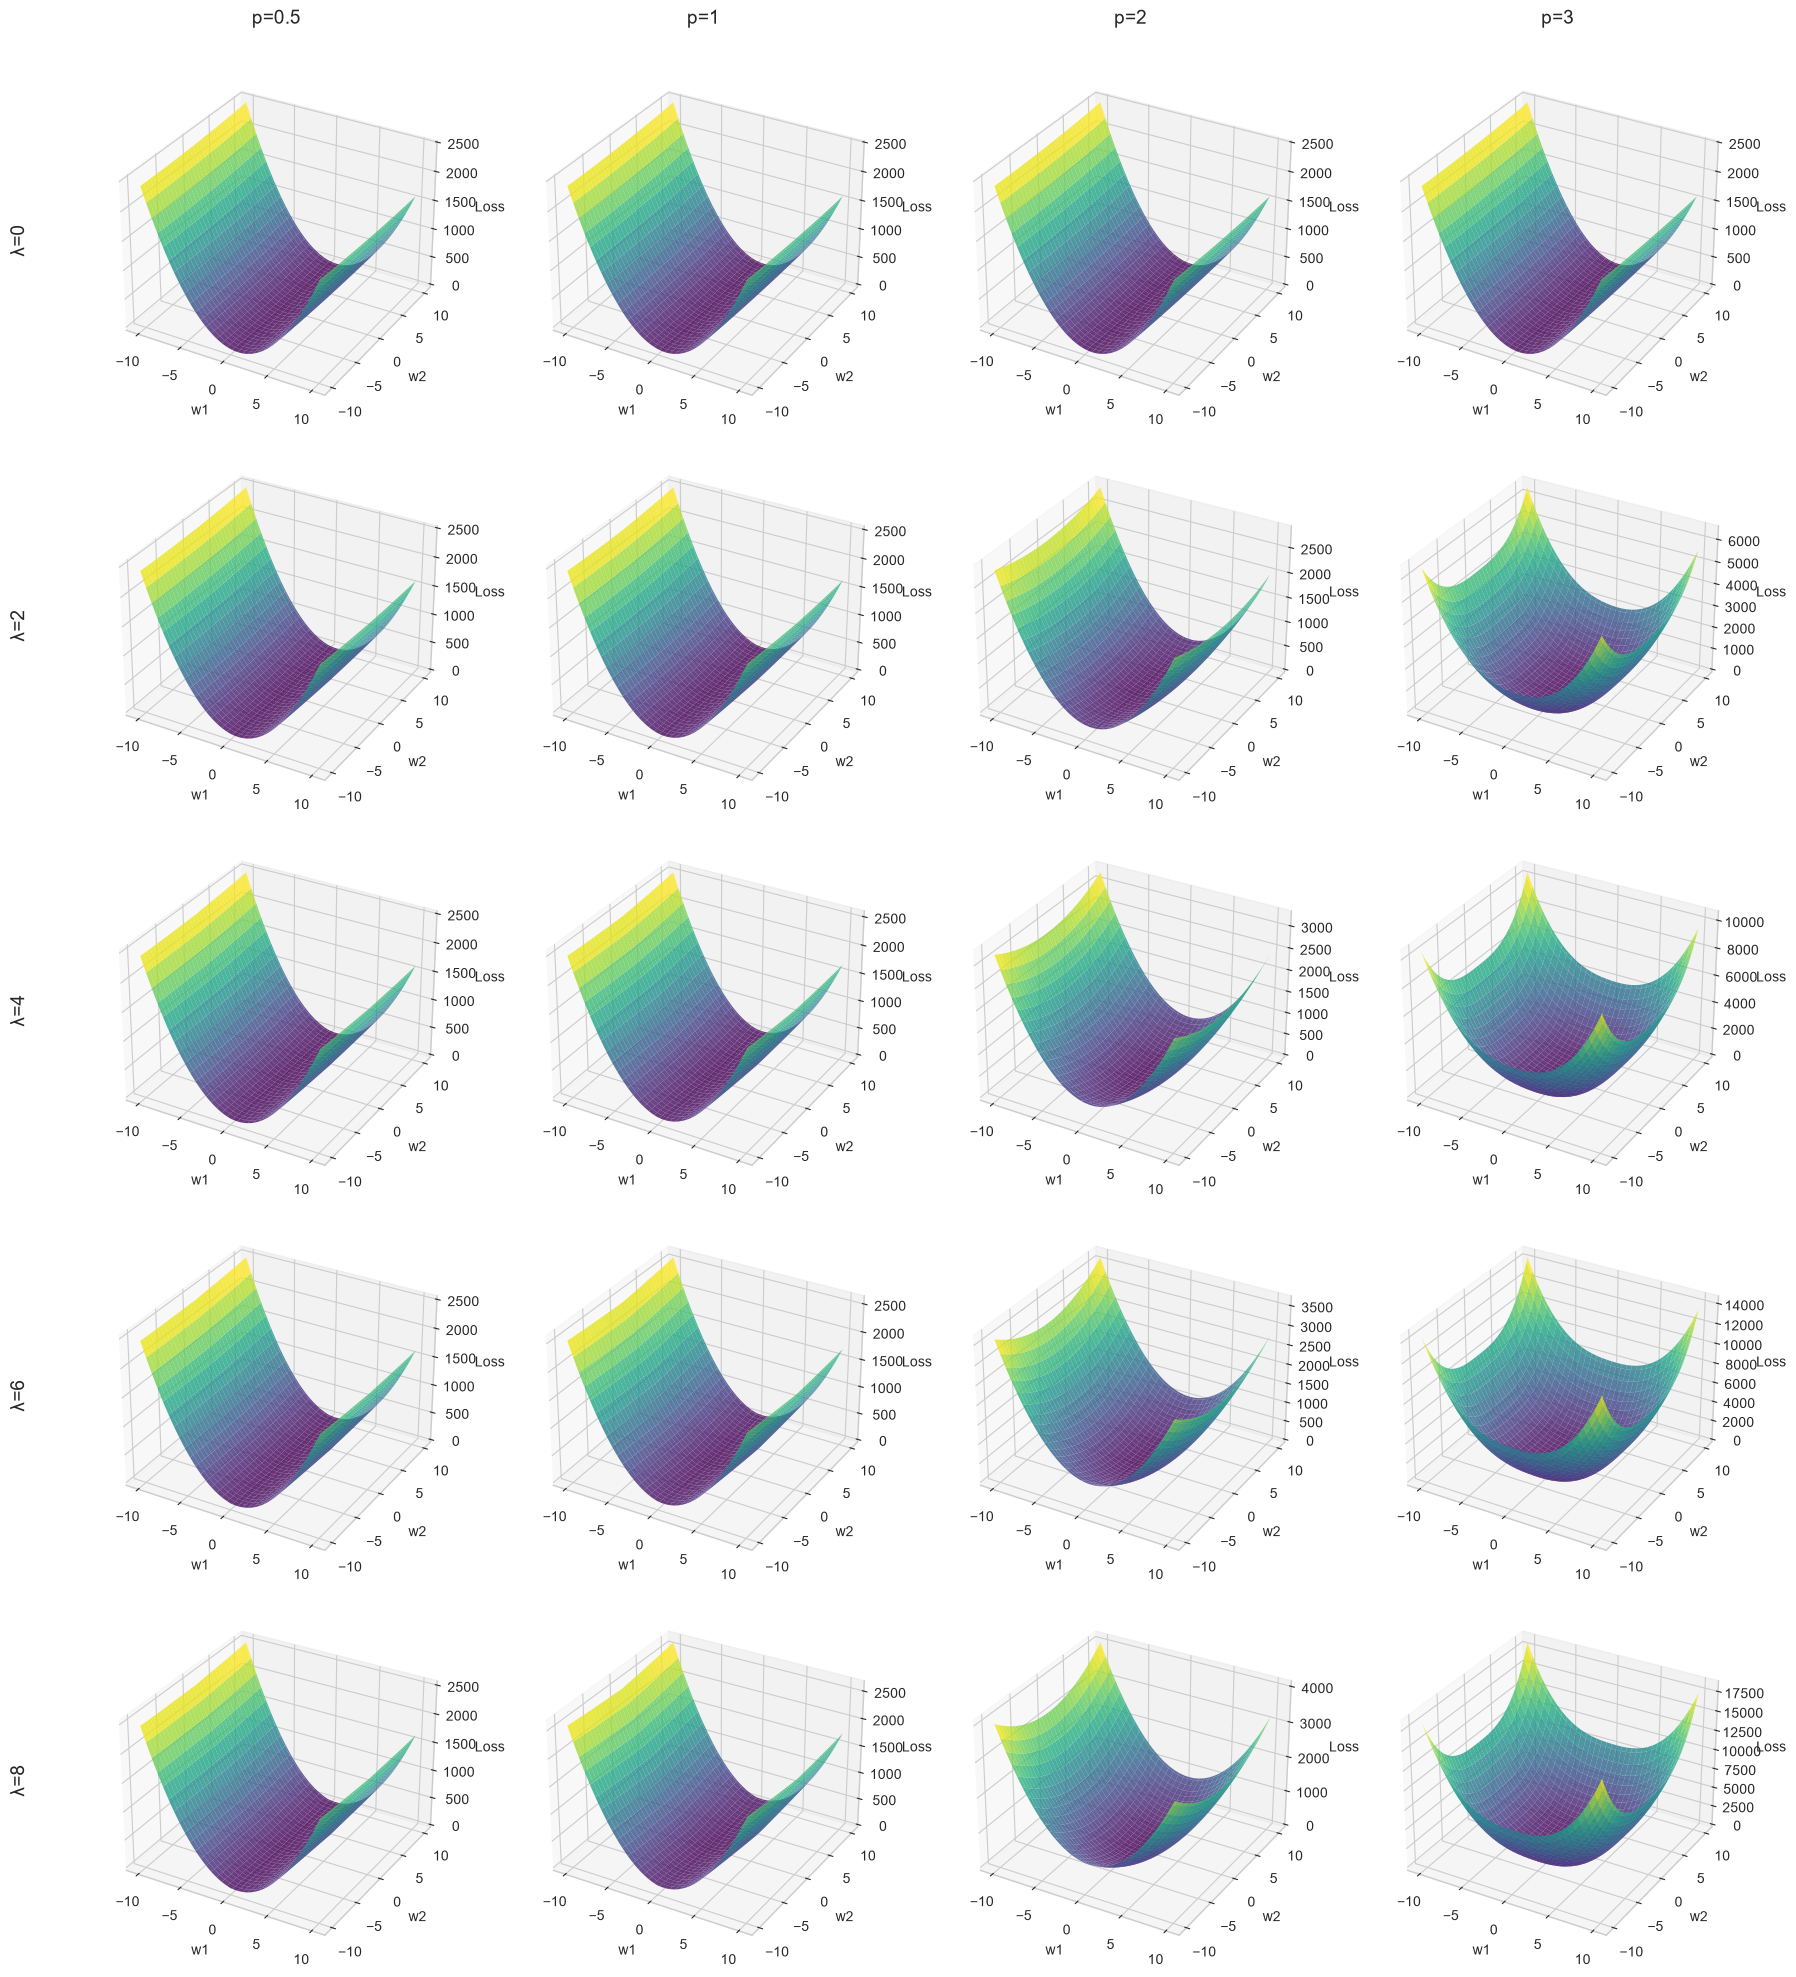

In [8]:
# p norm on the weights for dataset B: rows = lambdas from the ridge cell, columns = p
p = [0.5, 1, 2, 3]

def grid_argmin(L):
    """Weights (w1, w2) of the grid point with the lowest loss (no closed form for general p)."""
    i = np.argmin(L)
    return W0.ravel()[i], W1.ravel()[i]


def label_grid(fig, axes):
    """Column labels (p=...) above the top row and row labels (λ=...) left of the first column."""
    fig.tight_layout(rect=[0.03, 0, 1, 0.97])  # leave room for the labels
    for j, p_norm in enumerate(p):
        pos = axes[0, j].get_position()
        fig.text((pos.x0 + pos.x1) / 2, 0.985, f"p={p_norm}", ha="center", va="center", fontsize=14)
    for i, lam in enumerate(lambdas):
        pos = axes[i, 0].get_position()
        fig.text(0.012, (pos.y0 + pos.y1) / 2, f"λ={lam}", ha="center", va="center", rotation=90, fontsize=14)


# penalised loss L = r^T r + lambda * (|w1|^p + |w2|^p) for every (lambda, p) combination
L_pen = {
    (lam, p_norm): L_b + lam * (np.abs(W0) ** p_norm + np.abs(W1) ** p_norm)
    for lam in lambdas
    for p_norm in p
}

# grid of 3D surfaces
fig, axes = plt.subplots(
    len(lambdas), len(p), figsize=(4.5 * len(p), 4 * len(lambdas)), subplot_kw={"projection": "3d"}
)
for i, lam in enumerate(lambdas):
    for j, p_norm in enumerate(p):
        ax = axes[i, j]
        ax.plot_surface(W0, W1, L_pen[lam, p_norm], cmap="viridis", alpha=0.8)
        ax.set_xlabel("w1")
        ax.set_ylabel("w2")
        ax.set_zlabel("Loss")
label_grid(fig, axes)
plt.show()

## Task 3: could a neural network learn the OLS map?

**Yes, approximately.** OLS is a fixed function $(X, y) \mapsto \hat\beta$, smooth wherever $X^\top X$ is invertible, so a network can imitate it from examples. At test time it only does a forward pass (matrix multiplications and nonlinearities), with no inverse.

**Training data.** Each simulated dataset from $y = Xw + \varepsilon$ is one training example. Two details matter:
- $w$ has to be drawn anew for every dataset (e.g. $w \sim \mathcal{N}(0, I)$). If $w$ were the same in all 1000 datasets, the network could output that constant and ignore the data.
- $X$ should vary as well, including ill-conditioned designs like dataset B, otherwise the network never sees the hard cases.

**Inputs.** The whole dataset: $n$ rows $(x_i, y_i)$. For our problem (intercept + slope, $n = 20$) that is a $20 \times 3$ array (columns: bias $1$, $x_i$, $y_i$). The network sees every row of $(X, y)$ together, because $\hat\beta$ depends on all of them jointly.
- A plain MLP takes the flattened 60 numbers, so it needs a fixed $n$ and a fixed row order.
- $\hat\beta$ does not depend on row order, so a set-based network (DeepSets, or a transformer that treats each row as a token) fits better and handles any $n$.

**Outputs.** $\hat\beta \in \mathbb{R}^2$ (intercept, slope). A variant, used later for PFNs, also feeds in a query $x_\ast$ and outputs the prediction $\hat y_\ast = x_\ast^\top \hat\beta$.

**Loss.** Squared error against the OLS solution, $\lVert f_\theta(X, y) - \hat\beta_{\mathrm{OLS}} \rVert^2$. The inverse is only used once, offline, to make the labels.
- If the network is trained against the true $w$ instead, its optimum is the posterior mean $\mathbb{E}[w \mid X, y]$ under the prior on $w$, which is not OLS. For a Gaussian prior it is the ridge solution (Module 2).

**Caveats.**
- $\hat\beta = (X^\top X)^{-1} X^\top y$ is linear in $y$ but nonlinear in $X$. The network has to learn that nonlinearity in $X$ (and should standardise $y$, since $\hat\beta$ scales with it).
- Ill-conditioning makes the target hard. Along the weak eigenvector of $X^\top X$ the noise is amplified by $\approx 1/\sqrt{\lambda_{\min}}$. Dataset B (cond $\approx 74$) has a slope error about 5x larger than dataset A (cond $\approx 3.5$). As $\lambda_{\min} \to 0$ the map has unbounded slope, so the network will only be reliable on the kinds of $X$ it was trained on.
- 1000 datasets is small for a 60-dimensional input, but simulation is free. Generating fresh datasets at every training step gives an unlimited training set, which is the PFN idea (Module 6).